# Topografía de la Tierra (v2) · Copernicus GLO-30 en lugar de ASTER
**NASA Space Apps Challenge 2026** · Misma medida que `topografia_v1` (pendiente a 30 m y ~240 m, relieve local en ~1,2 km), con otro modelo de elevación:

| Cambio | v1 | v2 |
|---|---|---|
| Modelo de elevación | NASA ASTER GDEM v3 (30 m) | **Copernicus DEM GLO-30** (30 m, ESA/Airbus, TanDEM-X) |
| Ruido vertical | varios metros: el relieve de las llanuras no baja de 15–20 m | RMSE ~1,7 m frente a ICESat: llanuras lisas medibles |
| Cobertura | 83° N–83° S | global |
| Rejilla de ~240 m | bloques de 8 × 8 píxeles | 8 píxeles en latitud y los que den ~240 m en longitud (por encima de 50° el píxel de Copernicus es más ancho) |
| Intervalos del relieve | 5 m | **1 m** |

**Por qué**: en v1 los mares lunares más llanos (Apollo 12, Surveyor 1 y 3, Chang'e 3, 5 y 6) y las llanuras más lisas de Marte (Viking 1, InSight, Arcadia, Erebus) se quedaban sin pareja porque ninguna región de la Tierra bajaba de 15–20 m de relieve, en parte por el ruido de ASTER.

**Acceso**: teselas COG de 1° en el bucket público de AWS `copernicus-dem-30m` (sin cuenta). Las teselas de mar no existen (404) y cuentan como «sin dato».

**Por tandas**, igual que v1: una tesela cada vez, resumen de unos KB en `03_datos/cache_api/topografia_v2/` y parada a los `MAX_MINUTOS`. **Si al final pone «⏸ Quedan teselas pendientes», vuelve a ejecutar la sección 3.**

## 0. Instalación

In [8]:
!pip install -q rasterio

## 1. Configuración

In [9]:
import os, re, gc, json, time, glob, datetime, unicodedata
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import requests, rasterio
from rasterio import features
from scipy import ndimage
from shapely.geometry import shape, box, Point
from shapely import affinity
from IPython.display import display
from google.colab import drive

drive.mount("/content/drive")
for raiz in ["/content/drive/MyDrive", "/content/drive/My Drive"]:
    if os.path.isdir(raiz):
        break
BASE = f"{raiz}/Hackathon Nasa"
VERSION = "topografia_v2"
RES, WEB = f"{BASE}/04_resultados/{VERSION}", f"{BASE}/06_web/{VERSION}"
CACHE = f"{BASE}/03_datos/cache_api/topografia_v2"
TMP = "/content/tmp/topografia_v2"
for d in (RES, WEB, CACHE, TMP):
    os.makedirs(d, exist_ok=True)

# --- Parámetros de las tandas ---
MAX_MINUTOS = 40                     # tiempo máximo por ejecución; luego se para y guarda (vuelve a ejecutar para seguir)
RADIO_ANALOGO_KM = 10                # círculo alrededor de cada análogo conocido
LADO_RELIEVE_M = 1200                # ventana del relieve local (desnivel máximo − mínimo)
PASO_BIN = 0.25; BINS = np.arange(0, 90 + PASO_BIN, PASO_BIN)        # pendiente (grados)
PASO_REL = 1; BINS_REL = np.arange(0, 3000 + PASO_REL, PASO_REL)      # relieve local (m), intervalos de 1 m

FIGURAS = f"{RES}/figuras"; os.makedirs(FIGURAS, exist_ok=True)
_mostrar = getattr(plt, "_show_original", plt.show); plt._show_original = _mostrar
_n_fig = [0]
def _mostrar_y_guardar(*a, **k):
    fig = plt.gcf()
    if fig.axes:
        _n_fig[0] += 1
        titulo = next((ax.get_title() for ax in fig.axes if ax.get_title()), "figura")
        slug = re.sub(r"[^a-zA-Z0-9]+", "_", unicodedata.normalize("NFKD", titulo).encode("ascii", "ignore").decode()).strip("_").lower()[:50]
        fig.savefig(f"{FIGURAS}/fig_{_n_fig[0]:02d}_{slug}.png", dpi=80, bbox_inches="tight")
    _mostrar(*a, **k)
plt.show = _mostrar_y_guardar

COP_URL = "https://copernicus-dem-30m.s3.amazonaws.com"      # bucket público de AWS (sin cuenta)
PIXEL_240_M = 240                                             # tamaño objetivo de la rejilla gruesa
SESION = requests.Session()
entrada = json.load(open(f"{BASE}/06_web/manifest.json", encoding="utf-8"))
print("Copernicus GLO-30 en", COP_URL, "| cuerpos:", {k: v["carpeta"] for k, v in entrada["cuerpos"].items()})

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Copernicus GLO-30 en https://copernicus-dem-30m.s3.amazonaws.com | cuerpos: {'marte': 'v1.3', 'luna': 'luna_v0.3'}


## 2. Qué se mide: regiones candidatas (completas) y análogos conocidos
Los análogos conocidos salen de `analogos.geojson` de cada cuerpo (los verificados de la ficha). Cada uno se mide en un círculo de 10 km.

In [10]:
def nombre_tesela(lat0, lon0):
    return f"{'N' if lat0 >= 0 else 'S'}{abs(lat0):02d}{'E' if lon0 >= 0 else 'W'}{abs(lon0):03d}"

def teselas_de(g):
    oeste, sur, este, norte = g.bounds
    out = []
    for la in range(int(np.floor(sur)), int(np.ceil(norte))):
        for lo in range(int(np.floor(oeste)), int(np.ceil(este))):
            if g.intersects(box(lo, la, lo + 1, la + 1)):
                out.append((nombre_tesela(la, lo), la, lo))
    return out

def circulo_grados(lon, lat, radio_km):
    """Círculo de radio_km alrededor de un punto, como elipse en grados (vale para radios pequeños)."""
    rlat = radio_km / 111.32
    return affinity.scale(Point(lon, lat).buffer(rlat, 64), xfact=1 / max(np.cos(np.radians(lat)), 0.05), yfact=1)

filas = []
for cuerpo in ["luna", "marte"]:
    info = entrada["cuerpos"][cuerpo]
    gj = json.load(open(f"{BASE}/06_web/{info['carpeta']}/regiones.geojson", encoding="utf-8"))
    for ft in gj["features"]:
        g = shape(ft["geometry"]); p = ft["properties"]
        filas.append({"region_id": p["id"], "cuerpo": cuerpo, "tipo": "region_candidata", "region": p.get("region"), "geom": g})
    an = json.load(open(f"{BASE}/06_web/{info['carpeta']}/analogos.geojson", encoding="utf-8"))
    for ft in an["features"]:
        p = ft["properties"]
        ok = (p.get("tipo") in ("analogo_luna", "impacto")) if cuerpo == "luna" else (p.get("verificacion") == "verificada")
        if not ok or not ft.get("geometry"):
            continue
        lon, lat = ft["geometry"]["coordinates"][:2]
        slug = re.sub(r"[^a-z0-9]+", "-", unicodedata.normalize("NFKD", p["nombre"]).encode("ascii", "ignore").decode().lower()).strip("-")[:40]
        filas.append({"region_id": f"analogo-{cuerpo}-{slug}", "cuerpo": cuerpo, "tipo": "analogo_conocido", "region": p["nombre"],
                      "geom": circulo_grados(lon, lat, RADIO_ANALOGO_KM)})
regiones = pd.DataFrame(filas)
regiones["teselas"] = regiones.geom.map(teselas_de)
regiones = regiones[regiones.teselas.str.len() > 0].reset_index(drop=True)
regiones.drop(columns="geom").assign(n_teselas=regiones.teselas.str.len()).drop(columns="teselas") \
    .to_csv(f"{RES}/regiones_v1.csv", index=False)

trabajo = [(r.region_id, t) for r in regiones.itertuples() for t in r.teselas]
hecha = lambda rid, t: os.path.exists(f"{CACHE}/{rid}__{t[0]}.npz")
hechas = sum(hecha(rid, t) for rid, t in trabajo)
print(f"{(regiones.tipo == 'region_candidata').sum()} regiones candidatas + {(regiones.tipo == 'analogo_conocido').sum()} análogos conocidos")
print(f"{len(trabajo)} teselas en total | ya procesadas: {hechas} | pendientes: {len(trabajo) - hechas}")
print(f"Pendiente: ~{(len(trabajo) - hechas) * 30 / 1000:.0f} GB de descarga temporal (no ocupa Drive) y "
      f"~{(len(trabajo) - hechas) * 4 / 60:.0f} min aprox.; en Drive solo ~{(len(trabajo) - hechas) * 12 / 1000:.0f} MB")
display(regiones.assign(n_teselas=regiones.teselas.str.len()).sort_values("n_teselas", ascending=False)[["region_id", "region", "tipo", "n_teselas"]].head(12))

41 regiones candidatas + 15 análogos conocidos
1053 teselas en total | ya procesadas: 1014 | pendientes: 39
Pendiente: ~1 GB de descarga temporal (no ocupa Drive) y ~3 min aprox.; en Drive solo ~0 MB


,region_id,region,tipo,n_teselas
38,marte_arido-1,Argelia,region_candidata,557
39,marte_arido-2,"Provincia de Riad, Arabia Saudita",region_candidata,75
41,marte_arido-4,"Sinkiang, China",region_candidata,75
27,marte_polar-1,Groenlandia,region_candidata,71
35,marte_altura-1,"Sinkiang, China",region_candidata,40
29,marte_polar-3,"Nunavut, Canadá",region_candidata,22
0,luna-1,"Afar, Etiopía",region_candidata,19
40,marte_arido-3,"Región de Antofagasta, Chile",region_candidata,16
43,marte_arido-6,"Provincia Oriental, Arabia Saudita",region_candidata,11
46,marte_arido-9,"Mongolia Interior, China",region_candidata,11


## 3. Procesado por tandas (Copernicus GLO-30)
Para cada tesela: descarga a la carpeta temporal → pendiente a 30 m → promedio a ~240 m → pendiente y relieve local a ~240 m →
histogramas a Drive → borrado del archivo y liberación de memoria. **Vuelve a ejecutar esta celda si queda trabajo pendiente.**

In [11]:
M_POR_SEG = 30.87                                         # metros por segundo de arco (latitud)

def pendiente(z, dy, dx_filas):
    gy, gx = np.gradient(z)
    gx /= np.asarray(dx_filas, dtype="float32")[:, None]; gy /= np.float32(dy)
    np.hypot(gx, gy, out=gx); del gy
    return np.degrees(np.arctan(gx, out=gx), out=gx)

def impar(n):
    n = max(int(round(n)), 3)                             # como mínimo 3 × 3 píxeles
    return n if n % 2 else n + 1

def relieve(z, dy, dx):
    """Desnivel (máximo − mínimo) en una ventana de ~LADO_RELIEVE_M; NaN si la ventana toca huecos de datos."""
    tam = (impar(LADO_RELIEVE_M / dy), impar(LADO_RELIEVE_M / dx))
    hueco = ~np.isfinite(z)
    zf = np.where(hueco, np.nanmean(z) if np.isfinite(z).any() else 0, z)
    r = ndimage.maximum_filter(zf, size=tam) - ndimage.minimum_filter(zf, size=tam)
    r[ndimage.maximum_filter(hueco.astype(np.uint8), size=tam) > 0] = np.nan
    return r

def url_cop(tesela):
    _, la, lo = tesela
    n = f"Copernicus_DSM_COG_10_{'N' if la >= 0 else 'S'}{abs(la):02d}_00_{'E' if lo >= 0 else 'W'}{abs(lo):03d}_00_DEM"
    return f"{COP_URL}/{n}/{n}.tif"

class SinTesela(Exception):
    pass

def descargar(url, destino):
    with SESION.get(url, stream=True, timeout=300) as r:
        if r.status_code in (403, 404):          # mar: Copernicus no publica la tesela
            raise SinTesela(url)
        r.raise_for_status()
        with open(destino, "wb") as f:
            for trozo in r.iter_content(1 << 22):
                f.write(trozo)

def procesar(geom, tesela, url):
    nombre = tesela[0]
    ruta = f"{TMP}/{nombre}_dem.tif"
    descargar(url, ruta)
    try:
        with rasterio.open(ruta) as src:
            z = src.read(1).astype("float32"); tr = src.transform
    finally:
        os.remove(ruta)
    z[(z < -500) | (z == 0)] = np.nan            # 0 exacto = mar aplanado en las teselas de costa
    mascara = features.geometry_mask([geom], out_shape=z.shape, transform=tr, invert=True)
    if not mascara.any():
        return {"sin_dato": True}
    lat_filas = tr.f + tr.e * (np.arange(z.shape[0]) + 0.5)
    dx = M_POR_SEG * abs(tr.a) * 3600 * np.cos(np.radians(lat_filas)); dy = M_POR_SEG * abs(tr.e) * 3600
    s30 = pendiente(z, dy, dx)
    ok = mascara & np.isfinite(s30)
    h30 = np.histogram(s30[ok], BINS)[0]; n30 = int(ok.sum())
    zr = z[ok]; z_sum, z_n = float(np.nansum(zr)), int(np.isfinite(zr).sum())
    z_min, z_max = (float(np.nanmin(zr)), float(np.nanmax(zr))) if zr.size else (np.nan, np.nan)
    del s30, ok, zr
    ky = max(int(round(PIXEL_240_M / dy)), 1)                       # ~240 m en latitud (8 píxeles de 1")
    kx = max(int(round(PIXEL_240_M / float(np.mean(dx)))), 1)      # ~240 m en longitud (el píxel se ensancha por encima de 50°)
    n = (z.shape[0] // ky) * ky, (z.shape[1] // kx) * kx
    with np.errstate(all="ignore"):
        z8 = np.nanmean(z[:n[0], :n[1]].reshape(n[0] // ky, ky, n[1] // kx, kx), axis=(1, 3))
    m8 = mascara[:n[0], :n[1]].reshape(n[0] // ky, ky, n[1] // kx, kx).mean(axis=(1, 3)) >= 0.5
    del z, mascara
    dx8 = dx[:n[0]].reshape(-1, ky).mean(1) * kx
    s240 = pendiente(z8, dy * ky, dx8)
    rel = relieve(z8, dy * ky, float(np.mean(dx8)))
    ok240, okr = m8 & np.isfinite(s240), m8 & np.isfinite(rel)
    out = {"h30": h30, "n30": n30, "h240": np.histogram(s240[ok240], BINS)[0],
           "hrel": np.histogram(np.clip(rel[okr], 0, BINS_REL[-1] - 0.01), BINS_REL)[0],
           "z_sum": z_sum, "z_n": z_n, "z_min": z_min, "z_max": z_max}
    del z8, m8, s240, rel
    return out

t0, nuevas, errores, parado = time.time(), 0, 0, False
for r in regiones.itertuples():
    pendientes = [t for t in r.teselas if not hecha(r.region_id, t)]
    if not pendientes:
        continue
    if (time.time() - t0) / 60 > MAX_MINUTOS:
        parado = True; break
    for t in pendientes:
        if (time.time() - t0) / 60 > MAX_MINUTOS:
            parado = True; break
        destino = f"{CACHE}/{r.region_id}__{t[0]}.npz"
        try:
            np.savez(destino, **procesar(r.geom, t, url_cop(t)))
            nuevas += 1
        except SinTesela:
            np.savez(destino, sin_dato=True)
        except Exception as e:
            errores += 1
            print(f"  ⚠ {r.region_id} {t[0]}: {e!r} (se reintentará en la próxima ejecución)")
        gc.collect()
        if nuevas % 25 == 0 and nuevas:
            hechas = sum(hecha(rid, tt) for rid, tt in trabajo)
            print(f"  {hechas}/{len(trabajo)} teselas · {(time.time() - t0) / 60:.0f} min · ahora: {r.region_id}")
    if parado:
        break

hechas = sum(hecha(rid, t) for rid, t in trabajo)
print(f"\nNuevas en esta ejecución: {nuevas} · errores: {errores} · total procesadas: {hechas} de {len(trabajo)} "
      f"({(time.time() - t0) / 60:.0f} min)")
TERMINADO = hechas == len(trabajo)
print("✅ Todas las teselas procesadas." if TERMINADO else "⏸ Quedan teselas pendientes: vuelve a ejecutar esta celda (o el notebook) para continuar.")

/tmp/ipykernel_7025/1901288979.py:64: RuntimeWarning: Mean of empty slice
  z8 = np.nanmean(z[:n[0], :n[1]].reshape(n[0] // ky, ky, n[1] // kx, kx), axis=(1, 3))
/tmp/ipykernel_7025/1901288979.py:64: RuntimeWarning: Mean of empty slice
  z8 = np.nanmean(z[:n[0], :n[1]].reshape(n[0] // ky, ky, n[1] // kx, kx), axis=(1, 3))
/tmp/ipykernel_7025/1901288979.py:64: RuntimeWarning: Mean of empty slice
  z8 = np.nanmean(z[:n[0], :n[1]].reshape(n[0] // ky, ky, n[1] // kx, kx), axis=(1, 3))
/tmp/ipykernel_7025/1901288979.py:64: RuntimeWarning: Mean of empty slice
  z8 = np.nanmean(z[:n[0], :n[1]].reshape(n[0] // ky, ky, n[1] // kx, kx), axis=(1, 3))


  1039/1053 teselas · 1 min · ahora: marte_arido-10


/tmp/ipykernel_7025/1901288979.py:64: RuntimeWarning: Mean of empty slice
  z8 = np.nanmean(z[:n[0], :n[1]].reshape(n[0] // ky, ky, n[1] // kx, kx), axis=(1, 3))
/tmp/ipykernel_7025/1901288979.py:64: RuntimeWarning: Mean of empty slice
  z8 = np.nanmean(z[:n[0], :n[1]].reshape(n[0] // ky, ky, n[1] // kx, kx), axis=(1, 3))
/tmp/ipykernel_7025/1901288979.py:64: RuntimeWarning: Mean of empty slice
  z8 = np.nanmean(z[:n[0], :n[1]].reshape(n[0] // ky, ky, n[1] // kx, kx), axis=(1, 3))
/tmp/ipykernel_7025/1901288979.py:64: RuntimeWarning: Mean of empty slice
  z8 = np.nanmean(z[:n[0], :n[1]].reshape(n[0] // ky, ky, n[1] // kx, kx), axis=(1, 3))
/tmp/ipykernel_7025/1901288979.py:64: RuntimeWarning: Mean of empty slice
  z8 = np.nanmean(z[:n[0], :n[1]].reshape(n[0] // ky, ky, n[1] // kx, kx), axis=(1, 3))
/tmp/ipykernel_7025/1901288979.py:64: RuntimeWarning: Mean of empty slice
  z8 = np.nanmean(z[:n[0], :n[1]].reshape(n[0] // ky, ky, n[1] // kx, kx), axis=(1, 3))
/tmp/ipykernel_7025/19012889


Nuevas en esta ejecución: 39 · errores: 0 · total procesadas: 1053 de 1053 (1 min)
✅ Todas las teselas procesadas.


## 4. Resumen por región y por análogo

In [12]:
def estadisticas(h, bins=BINS, umbrales=(5, 10, 15)):
    h = np.asarray(h, float); tot = h.sum()
    if tot == 0:
        return dict(mediana=np.nan, p90=np.nan, **{f"pct_lt{u}": np.nan for u in umbrales})
    acum = np.cumsum(h) / tot
    q = lambda p: float(bins[1:][np.searchsorted(acum, p)])
    paso = bins[1] - bins[0]
    return dict(mediana=q(0.5), p90=q(0.9), **{f"pct_lt{u}": float(acum[int(round(u / paso)) - 1] * 100) for u in umbrales})

filas, HIST = [], {}
for r in regiones.itertuples():
    h30 = np.zeros(len(BINS) - 1); h240 = np.zeros(len(BINS) - 1); hrel = np.zeros(len(BINS_REL) - 1)
    zs = zn = 0; zmin, zmax = np.inf, -np.inf; hechas_r = 0
    for t in r.teselas:
        ruta = f"{CACHE}/{r.region_id}__{t[0]}.npz"
        if not os.path.exists(ruta):
            continue
        hechas_r += 1
        d = np.load(ruta)
        if "sin_dato" in d.files:
            continue
        h30 += d["h30"]; h240 += d["h240"]; hrel += d["hrel"]; zs += float(d["z_sum"]); zn += int(d["z_n"])
        zmin = min(zmin, float(d["z_min"])); zmax = max(zmax, float(d["z_max"]))
    HIST[r.region_id] = (h240, hrel)
    e30, e240, erel = estadisticas(h30), estadisticas(h240), estadisticas(hrel, BINS_REL, (50, 100, 200))
    filas.append({"region_id": r.region_id, "cuerpo": r.cuerpo, "tipo": r.tipo, "region": r.region,
                  "teselas_hechas": f"{hechas_r}/{len(r.teselas)}", "completa": hechas_r == len(r.teselas),
                  "elev_media_m": round(zs / zn) if zn else np.nan, "elev_min_m": round(zmin) if zn else np.nan,
                  "elev_max_m": round(zmax) if zn else np.nan,
                  **{f"{k}_30m": round(v, 1) for k, v in e30.items()}, **{f"{k}_240m": round(v, 1) for k, v in e240.items()},
                  **{f"relieve_{k}": round(v, 1) for k, v in erel.items()}})
topo = pd.DataFrame(filas)
topo.to_csv(f"{RES}/topografia_regiones_v2.csv", index=False)
print("Regiones completas:", int(topo.completa.sum()), "de", len(topo))
cols = ["region_id", "region", "teselas_hechas", "mediana_240m", "pct_lt10_240m", "relieve_mediana", "relieve_p90"]
display(topo[topo.tipo == "region_candidata"][cols])
display(topo[topo.tipo == "analogo_conocido"][cols])

Regiones completas: 56 de 56


,region_id,region,teselas_hechas,mediana_240m,pct_lt10_240m,relieve_mediana,relieve_p90
0,luna-1,"Afar, Etiopía",19/19,1.5,90.7,37.0,181.0
1,luna-2,"Gobernacion de Rif Dimashq, Siria",10/10,1.0,98.1,19.0,69.0
2,luna-3,"Provincia de Medina, Arabia Saudita",5/5,1.0,98.8,22.0,59.0
3,luna-4,"Afar, Etiopía",5/5,1.0,97.8,20.0,89.0
4,luna-5,"Condado de Marsabit, Kenia",4/4,1.0,98.6,20.0,67.0
5,luna-6,"Provincia de La Meca, Arabia Saudita",4/4,1.0,99.8,18.0,45.0
6,luna-7,Islandia,6/6,1.5,94.0,35.0,139.0
7,luna-8,"Afar, Etiopía",3/3,1.5,95.6,34.0,123.0
8,luna-9,"Provincia de Tabuk, Arabia Saudita",3/3,3.0,91.1,67.0,158.0
9,luna-10,"Tibesti, Chad",4/4,6.2,69.2,134.0,329.0


,region_id,region,teselas_hechas,mediana_240m,pct_lt10_240m,relieve_mediana,relieve_p90
20,analogo-luna-craters-of-the-moon-idaho,"Craters of the Moon, Idaho",1/1,1.0,94.5,20.0,107.0
21,analogo-luna-kilauea-hawai,"Kīlauea, Hawái",1/1,2.5,98.6,54.0,104.0
22,analogo-luna-pinacate-sonora,"Pinacate, Sonora",1/1,3.8,93.0,82.0,177.0
23,analogo-luna-askja-islandia,"Askja, Islandia",2/2,3.8,81.8,94.0,247.0
24,analogo-luna-lanzarote-timanfaya,Lanzarote – Timanfaya,2/2,3.0,89.5,71.0,185.0
25,analogo-luna-mauna-kea-hawai,"Mauna Kea, Hawái",1/1,12.5,30.5,264.0,388.0
26,analogo-luna-meteor-crater-arizona,"Meteor Crater, Arizona",4/4,1.0,99.7,17.0,28.0
48,analogo-marte-cuenca-de-qaidam-occidental-lenghu,Cuenca de Qaidam occidental (Lenghu),1/1,1.0,100.0,19.0,54.0
49,analogo-marte-isla-axel-heiberg-gypsum-hill-m-...,Isla Axel Heiberg (Gypsum Hill / M.A.R.S.),2/2,10.0,50.1,231.0,392.0
50,analogo-marte-isla-devon-haughton-mars-project,Isla Devon (Haughton-Mars Project),2/2,2.8,98.8,50.0,87.0


## 5. Cambios respecto a v1 (ASTER)
¿Baja el relieve de las llanuras al cambiar a Copernicus? Si el ruido de ASTER inflaba el relieve, las regiones llanas deberían bajar mucho y las abruptas casi nada.

Relieve mediano: ASTER 58 m → Copernicus 52 m (mediana de los lugares)
Mínimo entre los lugares: ASTER 15 m → Copernicus 5 m


,region_id,region,mediana_30m_aster,mediana_240m_aster,relieve_mediana_aster,relieve_p90_aster,mediana_30m_cop,mediana_240m_cop,relieve_mediana_cop,relieve_p90_cop,cambio_relieve_m
47,marte_arido-10,"Dajla-Río de Oro, Marruecos",5.5,0.8,15.0,20.0,0.8,0.2,5.0,9.0,-10.0
44,marte_arido-7,"Gobernación de Mutana, Irak",6.0,1.0,20.0,30.0,0.8,0.2,5.0,13.0,-15.0
46,marte_arido-9,"Mongolia Interior, China",6.2,1.0,20.0,60.0,1.0,0.5,6.0,47.0,-14.0
45,marte_arido-8,"Al Wahat, Libia",7.0,1.2,25.0,45.0,1.0,0.5,8.0,22.0,-17.0
42,marte_arido-5,"Gobernación de Shabwah, Yemen",5.8,1.0,20.0,130.0,1.2,0.5,9.0,126.0,-11.0
38,marte_arido-1,Argelia,6.5,1.2,25.0,65.0,1.0,0.5,10.0,54.0,-15.0
39,marte_arido-2,"Provincia de Riad, Arabia Saudita",4.5,1.0,20.0,50.0,1.5,0.5,11.0,44.0,-9.0
43,marte_arido-6,"Provincia Oriental, Arabia Saudita",5.2,1.0,20.0,30.0,1.2,0.5,12.0,25.0,-8.0
26,analogo-luna-meteor-crater-arizona,"Meteor Crater, Arizona",4.5,1.0,25.0,35.0,1.2,1.0,17.0,28.0,-8.0
5,luna-6,"Provincia de La Meca, Arabia Saudita",3.8,1.0,20.0,50.0,1.2,1.0,18.0,45.0,-2.0


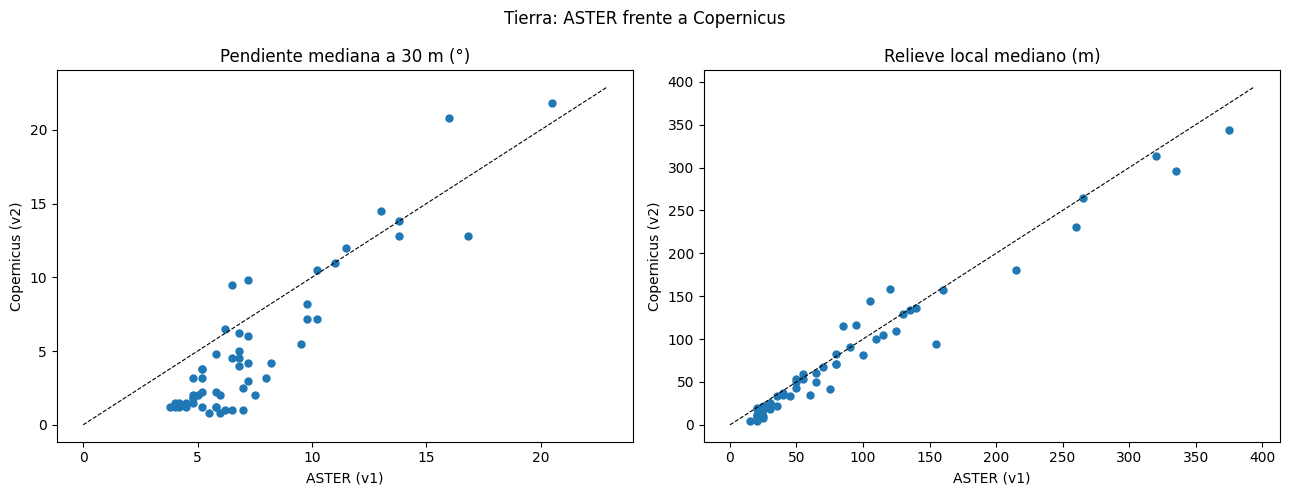

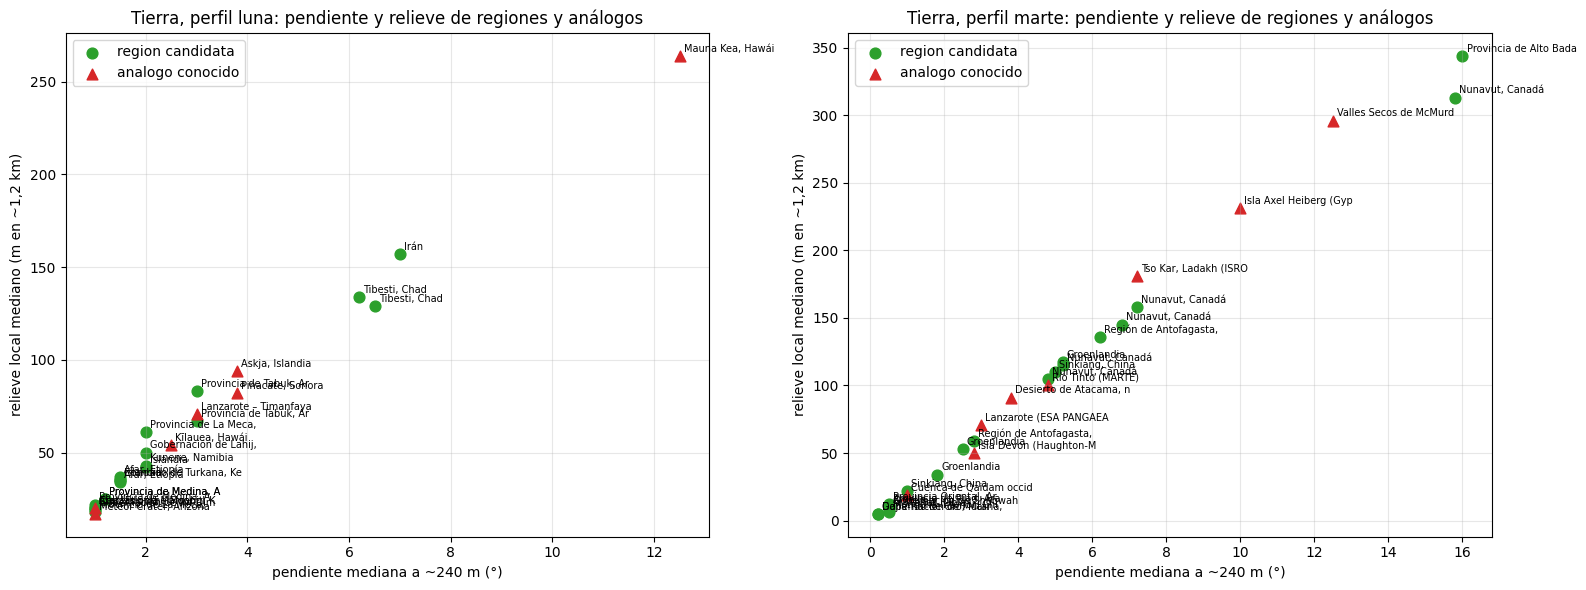

In [13]:
v1 = f"{BASE}/04_resultados/topografia_v1/topografia_regiones_v1.csv"
if os.path.exists(v1):
    cols_c = ["region_id", "region", "mediana_30m", "mediana_240m", "relieve_mediana", "relieve_p90"]
    comp = pd.read_csv(v1)[cols_c].merge(topo[cols_c], on=["region_id", "region"], suffixes=("_aster", "_cop"))
    comp["cambio_relieve_m"] = (comp.relieve_mediana_cop - comp.relieve_mediana_aster).round(1)
    print(f"Relieve mediano: ASTER {comp.relieve_mediana_aster.median():.0f} m → Copernicus {comp.relieve_mediana_cop.median():.0f} m (mediana de los lugares)")
    print(f"Mínimo entre los lugares: ASTER {comp.relieve_mediana_aster.min():.0f} m → Copernicus {comp.relieve_mediana_cop.min():.0f} m")
    display(comp.sort_values("relieve_mediana_cop").head(15))
    fig, ax = plt.subplots(1, 2, figsize=(13, 5))
    for a_, (x, y, t) in zip(ax, [("mediana_30m_aster", "mediana_30m_cop", "Pendiente mediana a 30 m (°)"),
                                  ("relieve_mediana_aster", "relieve_mediana_cop", "Relieve local mediano (m)")]):
        a_.scatter(comp[x], comp[y], s=25); lim = [0, max(comp[x].max(), comp[y].max()) * 1.05]
        a_.plot(lim, lim, "k--", lw=0.8); a_.set_xlabel("ASTER (v1)"); a_.set_ylabel("Copernicus (v2)"); a_.set_title(t)
    plt.suptitle("Tierra: ASTER frente a Copernicus"); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, cuerpo in zip(axes, ["luna", "marte"]):
    sel = topo[topo.cuerpo == cuerpo]
    for tipo, color, mk in (("region_candidata", "tab:green", "o"), ("analogo_conocido", "tab:red", "^")):
        s = sel[sel.tipo == tipo]
        ax.scatter(s.mediana_240m, s.relieve_mediana, c=color, marker=mk, s=60, label=tipo.replace("_", " "))
        for r in s.itertuples():
            ax.annotate(str(r.region)[:22], (r.mediana_240m, r.relieve_mediana), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax.set_xlabel("pendiente mediana a ~240 m (°)"); ax.set_ylabel("relieve local mediano (m en ~1,2 km)")
    ax.set_title(f"Tierra, perfil {cuerpo}: pendiente y relieve de regiones y análogos"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

## 6. Capa para la web y registro

In [14]:
def limpio(v):
    if isinstance(v, (float, np.floating)): return None if np.isnan(v) else float(v)
    if isinstance(v, (np.integer,)): return int(v)
    if isinstance(v, (np.bool_,)): return bool(v)
    return v

salida = {"version": VERSION, "unidades": {"pendiente": "grados", "relieve": "m (máximo − mínimo en ~1,2 km)", "elevacion": "m"},
          "escalas": {"30m": "Copernicus GLO-30 a resolución completa", "240m": "Copernicus promediado a ~240 m (pendiente y relieve)"},
          "regiones": {r["region_id"]: {k: limpio(v) for k, v in r.items() if k != "region_id"} for r in topo.to_dict("records")},
          "nota": "unir con regiones.geojson de cada cuerpo por region_id; los análogos conocidos tienen id analogo-<cuerpo>-<nombre>"}
json.dump(salida, open(f"{WEB}/topografia.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2, allow_nan=False)
if TERMINADO:
    entrada = json.load(open(f"{BASE}/06_web/manifest.json", encoding="utf-8"))
    entrada.setdefault("capas", {})["topografia"] = {"version": VERSION, "carpeta": VERSION, "archivo": f"{VERSION}/topografia.json"}
    json.dump(entrada, open(f"{BASE}/06_web/manifest.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
registro = {"version": VERSION, "fecha": datetime.datetime.now().isoformat(timespec="seconds"),
            "datos": "Copernicus DEM GLO-30 (ESA, 2021), doi:10.5270/ESA-c5d3d65; teselas COG del bucket público de AWS copernicus-dem-30m",
            "parametros": {"radio_analogo_km": RADIO_ANALOGO_KM, "lado_relieve_m": LADO_RELIEVE_M, "paso_relieve_m": PASO_REL, "pixel_240_m": PIXEL_240_M, "max_minutos": MAX_MINUTOS},
            "progreso": f"{sum(hecha(rid, t) for rid, t in trabajo)}/{len(trabajo)} teselas",
            "limitaciones": ["Copernicus es un modelo de superficie: incluye edificios y vegetación (irrelevante en las regiones desnudas, no en Kīlauea o Mauna Kea)",
                             "el mar de las teselas de costa (altura 0 exacta) se descarta",
                             "algunas teselas de Copernicus no son públicas (lista de la ESA); cuentan como sin dato"]}
json.dump(registro, open(f"{RES}/registro_{VERSION}.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2, default=str)
print("Guardado.", "Capa web registrada en el manifest." if TERMINADO else "La capa web se registrará cuando estén todas las teselas.")

Guardado. Capa web registrada en el manifest.


## 7. Conclusiones
*Rellenar cuando estén todas las teselas.*